Upload the two raw Excel files:
  0.2mm(sample 1).xlsx
  0.2mm(sample 2).xlsx


Saving 0.2mm(sample 1).xlsx to 0.2mm(sample 1).xlsx
Saving 0.2mm(sample 2).xlsx to 0.2mm(sample 2).xlsx


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")



MEASURED MASS AUDIT
           Sample  Instrument_Normalisation_Mass_g  Analysis_Active_Mass_g  Mass_Difference_percent                                 Mass_Source
0.2 mm (Sample 1)                          0.00945                 0.00945             0.000000e+00 Independently measured active material mass
0.2 mm (Sample 2)                          0.00990                 0.00990            -2.220446e-14 Independently measured active material mass

RATE TRANSITION
           Sample  Cycle_3_0.1C_Capacity_mAh_g  Cycle_4_1C_Capacity_mAh_g  Capacity_Change_percent  Capacity_Retained_at_Transition_percent
0.2 mm (Sample 1)                   170.885945                  86.643956               -49.297201                                50.702799
0.2 mm (Sample 2)                   163.152790                  91.789854               -43.739942                                56.260058

FINAL CYCLE RESULTS
           Sample  First_High_Current_Overall_Cycle  First_High_Current_Capacity_mAh_g  F

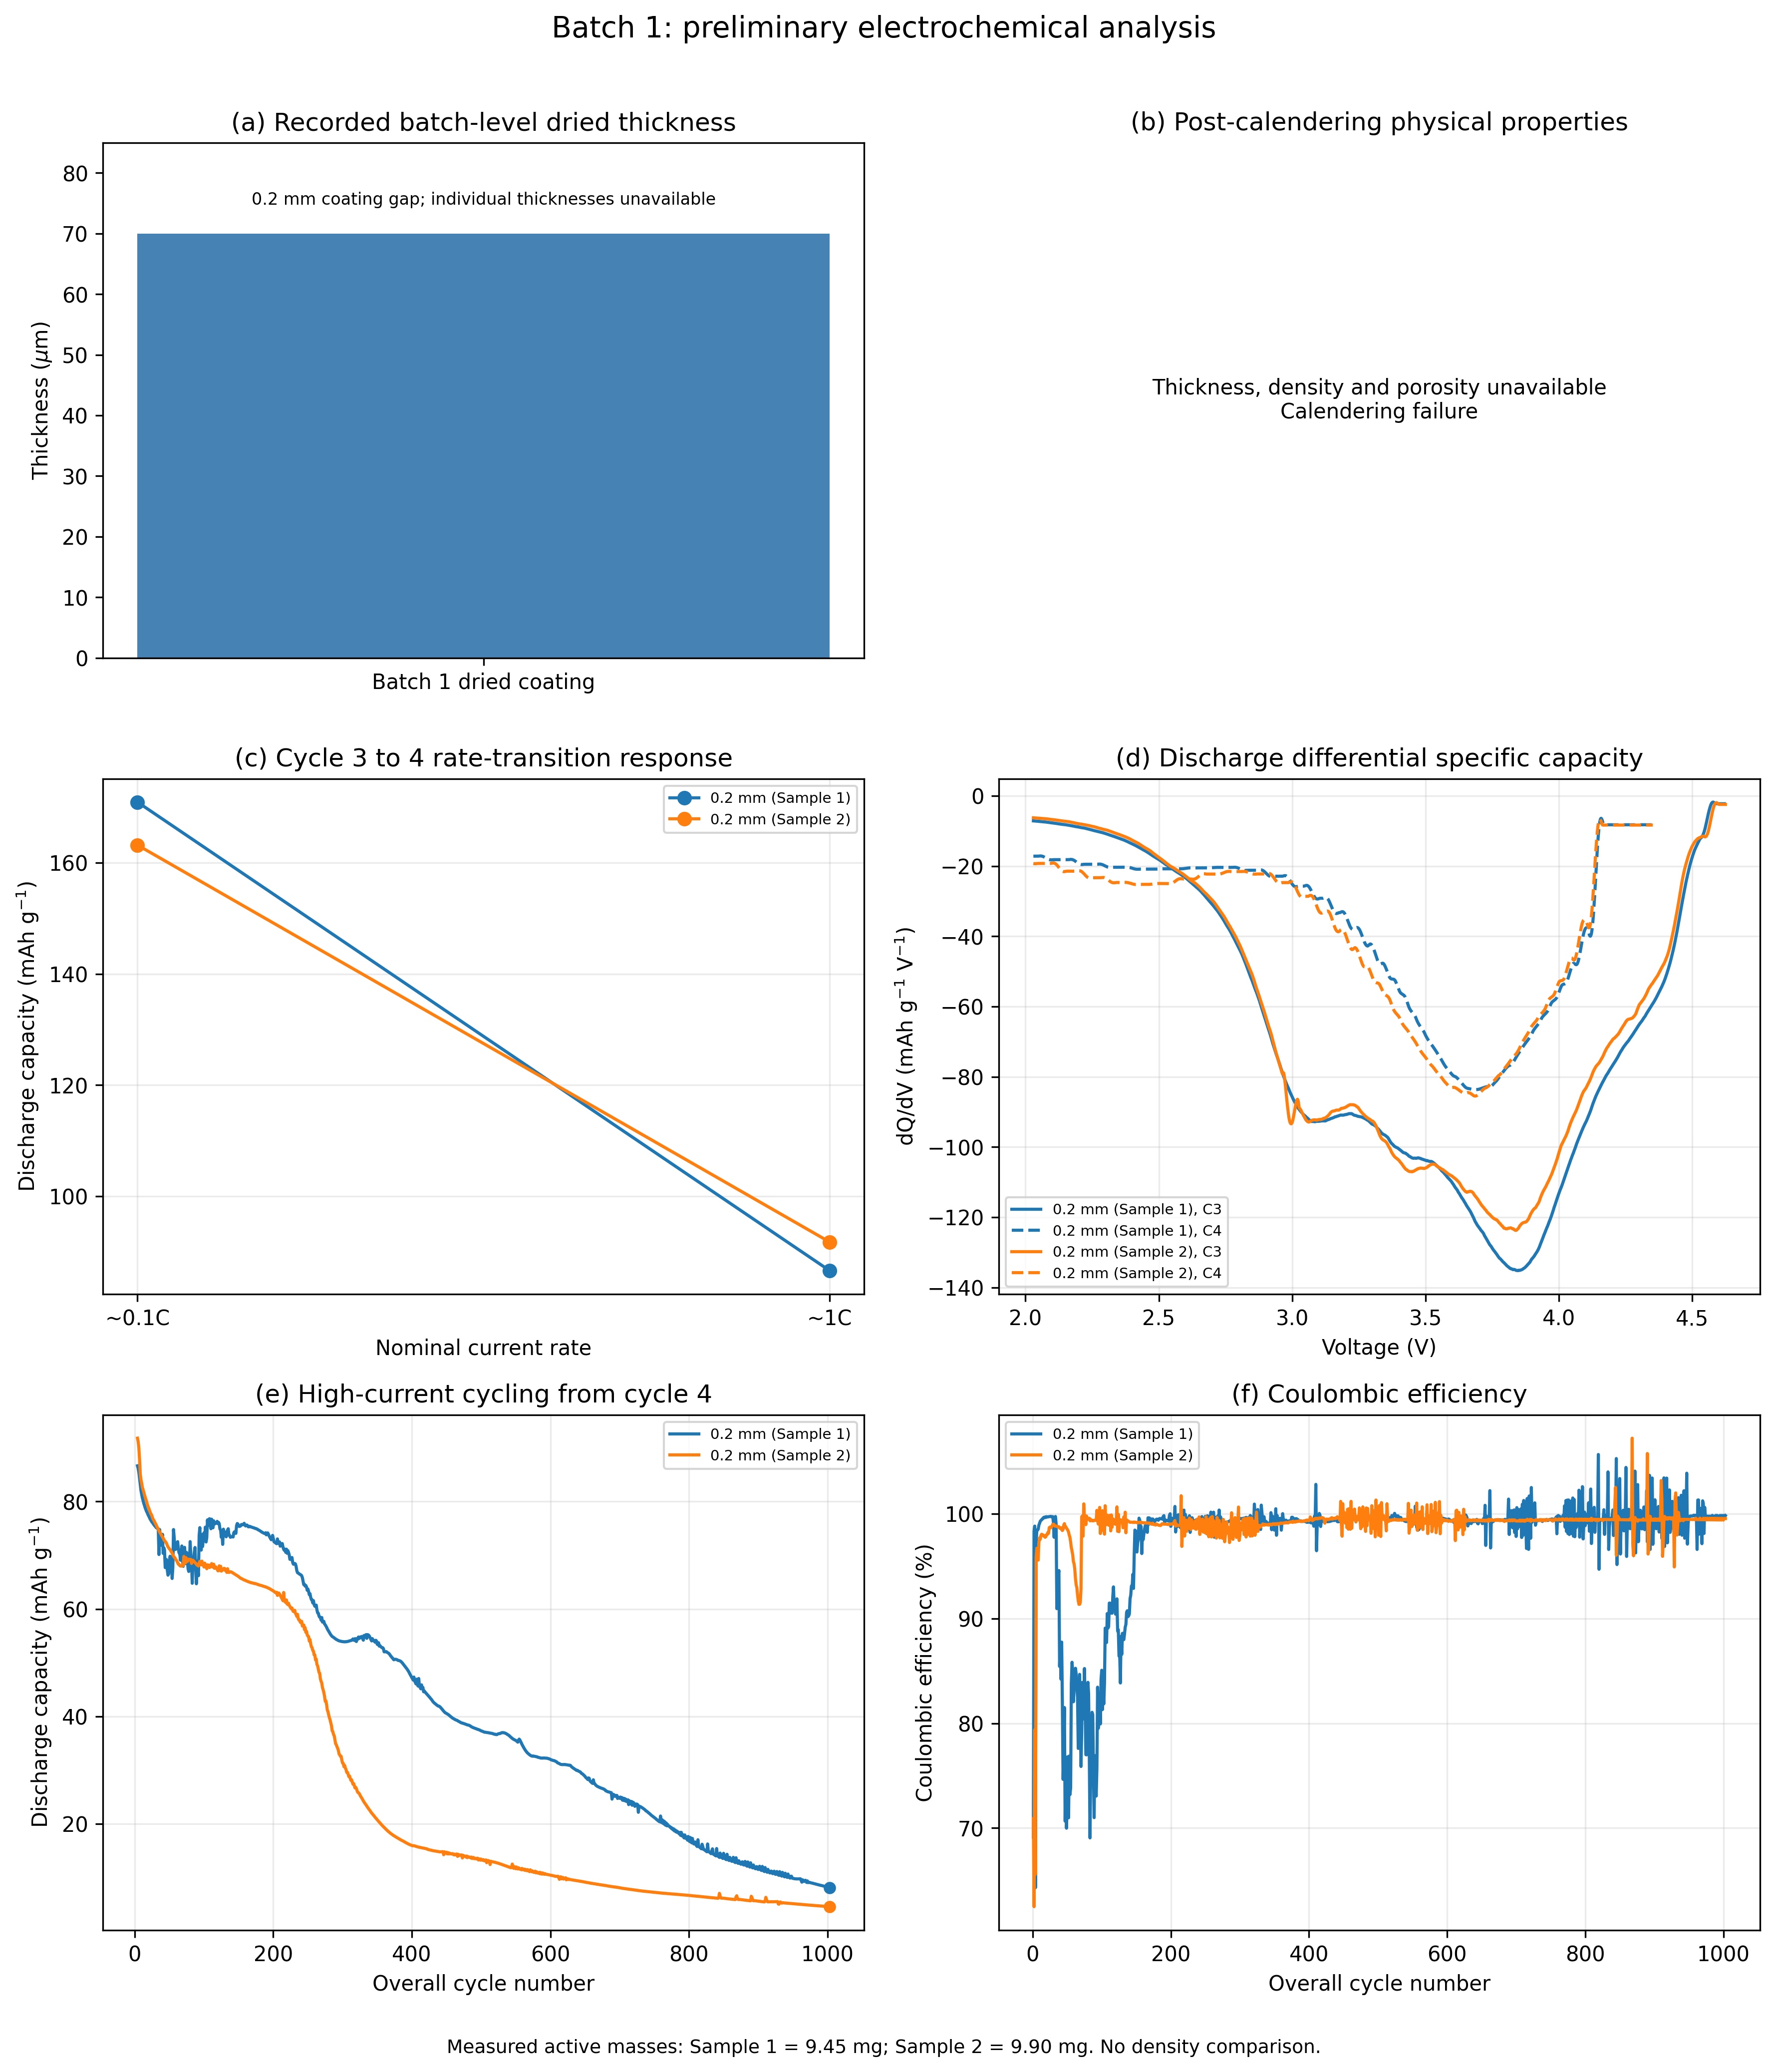

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
'0.2 mm is the coating-gap setting; 70 um is a batch-level dry thickness.'

from pathlib import Path
import argparse
import re
import sys
import zipfile

import numpy as np
import pandas as pd
import openpyxl
import matplotlib

matplotlib.use("Agg")

import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

# Independently measured active material masses.
# These values exclude the aluminium current collector.
MEASURED_ACTIVE_MASS_MG = {
    "0.2 mm (Sample 1)": 9.45,
    "0.2 mm (Sample 2)": 9.90,
}

THEORETICAL_CAPACITY_MAH_G = 250.0

FORMATION_LAST_CYCLE = 3
HIGH_CURRENT_START_CYCLE = 4
DQDV_CYCLES = (3, 4)

COATING_GAP_MM = 0.2
DRIED_THICKNESS_UM = 70.0
ELECTRODE_DIAMETER_MM = 16.0

VOLTAGE_STEP_V = 0.002
DQDV_MAX_WINDOW = 31
DQDV_POLYORDER = 3
MIN_DISCHARGE_POINTS = 15

SUMMARY_COLUMNS = [
    "Cycle_Index",
    "Chg_Cap_mAh",
    "DChg_Cap_mAh",
    "Chg_Spec_Cap_mAh_g",
    "DChg_Spec_Cap_mAh_g",
    "CE_percent",
    "Chg_Energy_Wh",
    "DChg_Energy_Wh",
    "Chg_Time_ms",
    "DChg_Time_ms",
    "DCIR_mOhm",
]

DETAIL_COLUMNS = [
    "Sample",
    "Cycle_Index",
    "Step_Type",
    "DataPoint",
    "Step_Time",
    "Total_Time",
    "Current_mA",
    "Voltage_V",
    "Capacity_mAh",
    "Energy_Wh",
    "Date",
]

def is_number(value):
    return (
        isinstance(value, (float, int))
        and not isinstance(value, bool)
        and np.isfinite(value)
    )

def get_sample_name(path):
    match = re.search(
        r"sample\s*([12])",
        path.stem,
        re.IGNORECASE,
    )

    if match is None:
        raise ValueError(
            f"Cannot identify the sample from {path.name}. "
            "The filename must contain Sample 1 or Sample 2."
        )

    return f"0.2 mm (Sample {match.group(1)})"

def read_raw_excel(path):
    sample = get_sample_name(path)

    workbook = openpyxl.load_workbook(
        path,
        read_only=True,
        data_only=True,
    )

    worksheet = workbook.active

    # Some BTS exports incorrectly declare A1:A1 as the sheet range.
    worksheet.reset_dimensions()

    summary_rows = []
    detail_rows = []
    current_cycle = None
    current_step = None

    try:
        for row in worksheet.iter_rows(values_only=True):
            values = list(row[:12])
            values += [None] * max(0, 12 - len(values))


            if is_number(values[0]):
                current_cycle = int(values[0])
                current_step = None
                summary_rows.append(values[:11])
                continue



            if (
                is_number(values[1])
                and isinstance(values[3], str)
            ):
                current_step = values[3].strip()
                continue






            is_detail_row = (
                current_cycle is not None
                and values[0] is None
                and values[1] is None
                and is_number(values[2])
                and float(values[2]).is_integer()
                and isinstance(values[3], str)
                and ":" in values[3]
                and isinstance(values[4], str)
                and ":" in values[4]
                and all(
                    is_number(values[index])
                    for index in (5, 6, 7)
                )
            )

            if is_detail_row:
                detail_rows.append([
                    sample,
                    current_cycle,
                    current_step,
                    int(values[2]),
                    values[3],
                    values[4],
                    values[5],
                    values[6],
                    values[7],
                    values[8],
                    values[9],
                ])

    finally:
        workbook.close()

    summary = pd.DataFrame(
        summary_rows,
        columns=SUMMARY_COLUMNS,
    )

    detail = pd.DataFrame(
        detail_rows,
        columns=DETAIL_COLUMNS,
    )

    if summary.empty or detail.empty:
        raise ValueError(
            f"No valid cycle summaries or point-level data: {path}"
        )

    summary["Cycle_Index"] = (
        summary["Cycle_Index"].astype(int)
    )

    if summary["Cycle_Index"].duplicated().any():
        raise ValueError(
            f"Duplicate cycle summary indices: {sample}"
        )

    summary["Sample"] = sample



    instrument_mass_ratios = []

    capacity_pairs = [
        ("Chg_Cap_mAh", "Chg_Spec_Cap_mAh_g"),
        ("DChg_Cap_mAh", "DChg_Spec_Cap_mAh_g"),
    ]

    for capacity_column, specific_column in capacity_pairs:
        valid = (
            (summary[capacity_column] > 0)
            & (summary[specific_column] > 0)
        )

        ratios = (
            summary.loc[valid, capacity_column]
            / summary.loc[valid, specific_column]
        )

        instrument_mass_ratios.extend(ratios.tolist())

    if not instrument_mass_ratios:
        raise ValueError(
            f"No valid capacity pairs for mass comparison: {sample}"
        )

    instrument_mass_g = float(
        np.median(instrument_mass_ratios)
    )

    if not np.allclose(
        instrument_mass_ratios,
        instrument_mass_g,
        rtol=1e-4,
        atol=1e-9,
    ):
        raise ValueError(
            f"The instrument normalisation mass changes "
            f"between cycles in {sample}. Inspect the raw data."
        )

    measured_mass_g = (
        MEASURED_ACTIVE_MASS_MG[sample] / 1000.0
    )

    if (
        not np.isfinite(measured_mass_g)
        or measured_mass_g <= 0
    ):
        raise ValueError(
            f"Invalid measured active material mass: {sample}"
        )



    for capacity_column, specific_column in capacity_pairs:
        summary["Raw_" + specific_column] = (
            summary[specific_column]
        )

        summary[specific_column] = (
            summary[capacity_column] / measured_mass_g
        )

    summary["Instrument_Normalisation_Mass_g"] = (
        instrument_mass_g
    )

    summary["Analysis_Active_Mass_g"] = measured_mass_g

    summary["Mass_Source"] = (
        "Independently measured active material mass"
    )

    summary["Mass_Difference_percent"] = (
        (instrument_mass_g / measured_mass_g - 1.0)
        * 100.0
    )


    summary["Raw_CE_percent"] = summary["CE_percent"]

    summary["CE_percent"] = (
        summary["DChg_Cap_mAh"]
        / summary["Chg_Cap_mAh"].where(
            summary["Chg_Cap_mAh"] > 0
        )
        * 100.0
    )

    detail["Analysis_Active_Mass_g"] = measured_mass_g

    detail["Calculated_C_Rate"] = (
        detail["Current_mA"].abs()
        / (
            measured_mass_g
            * THEORETICAL_CAPACITY_MAH_G
        )
    )



    current_records = []

    for cycle_number, group in detail.groupby(
        "Cycle_Index",
        sort=True,
    ):
        record = {
            "Cycle_Index": cycle_number,
        }

        direction_masks = [
            ("Charge", group["Current_mA"] > 1e-6),
            ("Discharge", group["Current_mA"] < -1e-6),
        ]

        for direction, mask in direction_masks:
            currents = (
                group.loc[mask, "Current_mA"].abs()
            )

            median_current = currents.median()

            record[
                f"{direction}_Median_Current_mA"
            ] = median_current

            record[
                f"{direction}_Median_C_Rate"
            ] = (
                median_current
                / (
                    measured_mass_g
                    * THEORETICAL_CAPACITY_MAH_G
                )
            )

            record[
                f"{direction}_Point_Count"
            ] = len(currents)

        current_records.append(record)

    summary = summary.merge(
        pd.DataFrame(current_records),
        on="Cycle_Index",
        how="left",
        validate="one_to_one",
    )



    summary["Protocol"] = np.where(
        summary["Cycle_Index"] <= FORMATION_LAST_CYCLE,
        "Low-current formation phase",
        "High-current cycling phase",
    )

    # Cycle 4 corresponds to high-current cycle 1.
    summary["High_Current_Cycle_Number"] = np.where(
        summary["Cycle_Index"] >= HIGH_CURRENT_START_CYCLE,
        summary["Cycle_Index"]
        - HIGH_CURRENT_START_CYCLE
        + 1,
        np.nan,
    )

    return summary, detail

def calculate_dqdv(detail, notes):
    'Retain negative discharge dQ/dV; normalise by measured active mass.'
    frames = []

    selected = detail[
        detail["Cycle_Index"].isin(DQDV_CYCLES)
    ]

    for (sample, cycle_number), group in selected.groupby(
        ["Sample", "Cycle_Index"]
    ):
        group = group[
            group["Current_mA"] < -1e-6
        ].copy()

        if len(group) < MIN_DISCHARGE_POINTS:
            notes.append(
                f"{sample}, cycle {cycle_number}: "
                f"dQ/dV excluded because fewer than "
                f"{MIN_DISCHARGE_POINTS} discharge points "
                "were available."
            )
            continue


        if (
            group["Capacity_mAh"]
            .diff()
            .dropna()
            .min()
            < -1e-5
        ):
            raise ValueError(
                f"Capacity reset within discharge: "
                f"{sample}, cycle {cycle_number}"
            )


        if (
            group["Voltage_V"].diff() > 0.01
        ).any():
            notes.append(
                f"{sample}, cycle {cycle_number}: "
                "a voltage reversal exceeding 10 mV "
                "was detected. Inspect the raw profile "
                "before interpreting differential peaks."
            )

        profile = (
            group.groupby(
                "Voltage_V",
                as_index=False,
            )["Capacity_mAh"]
            .mean()
            .sort_values("Voltage_V")
        )

        if len(profile) < MIN_DISCHARGE_POINTS:
            notes.append(
                f"{sample}, cycle {cycle_number}: "
                "dQ/dV excluded because too few "
                "unique voltage values were available."
            )
            continue

        voltage = np.arange(
            profile["Voltage_V"].min(),
            profile["Voltage_V"].max(),
            VOLTAGE_STEP_V,
        )

        if len(voltage) < MIN_DISCHARGE_POINTS:
            continue

        capacity = np.interp(
            voltage,
            profile["Voltage_V"],
            profile["Capacity_mAh"],
        )

        window = min(
            DQDV_MAX_WINDOW,
            (
                len(voltage)
                if len(voltage) % 2
                else len(voltage) - 1
            ),
        )

        capacity_smoothed = savgol_filter(
            capacity,
            window_length=window,
            polyorder=DQDV_POLYORDER,
        )

        derivative = savgol_filter(
            capacity,
            window_length=window,
            polyorder=DQDV_POLYORDER,
            deriv=1,
            delta=VOLTAGE_STEP_V,
        )

        edge = window // 2

        if len(voltage) - 2 * edge < MIN_DISCHARGE_POINTS:
            notes.append(
                f"{sample}, cycle {cycle_number}: "
                "dQ/dV excluded because too few points remain "
                "after edge trimming."
            )
            continue

        notes.append(
            f"{sample}, cycle {cycle_number}: dQ/dV uses "
            f"{len(group)} raw discharge points and "
            f"{len(profile)} unique voltages."
        )

        active_mass_g = (
            group["Analysis_Active_Mass_g"].iloc[0]
        )

        frames.append(
            pd.DataFrame({
                "Sample": sample,
                "Cycle_Index": cycle_number,
                "Voltage_V": voltage[edge:-edge],
                "Capacity_Smoothed_mAh":
                    capacity_smoothed[edge:-edge],
                "dQdV_mAh_per_V":
                    derivative[edge:-edge],
                "dQdV_mAh_g_per_V":
                    derivative[edge:-edge]
                    / active_mass_g,
            })
        )

    if frames:
        return pd.concat(
            frames,
            ignore_index=True,
        )

    return pd.DataFrame()

def create_six_panel_figure(
    summary,
    transition,
    long_term,
    dqdv,
    output_dir,
):
    figure, axes = plt.subplots(
        3,
        2,
        figsize=(12, 14),
    )

    colors = {
        "0.2 mm (Sample 1)": "tab:blue",
        "0.2 mm (Sample 2)": "tab:orange",
    }


    ax = axes[0, 0]

    ax.bar(
        ["Batch 1 dried coating"],
        [DRIED_THICKNESS_UM],
        color="steelblue",
    )

    ax.set(
        title="(a) Recorded batch-level dried thickness",
        ylabel="Thickness ($\\mu$m)",
        ylim=(0, 85),
    )

    ax.text(
        0.5,
        0.88,
        (
            "0.2 mm coating gap; "
            "individual thicknesses unavailable"
        ),
        transform=ax.transAxes,
        ha="center",
        fontsize=8,
    )


    ax = axes[0, 1]
    ax.axis("off")

    ax.set_title(
        "(b) Post-calendering physical properties"
    )

    ax.text(
        0.5,
        0.5,
        (
            "Thickness, density and porosity unavailable\n"
            "Calendering failure"
        ),
        transform=ax.transAxes,
        ha="center",
        va="center",
    )


    for sample, group in transition.groupby("Sample"):
        group = group.sort_values("Cycle_Index")

        axes[1, 0].plot(
            group["Rate_Label"],
            group["DChg_Spec_Cap_mAh_g"],
            "o-",
            label=sample,
            color=colors[sample],
        )

    axes[1, 0].set(
        title="(c) Cycle 3 to 4 rate-transition response",
        xlabel="Nominal current rate",
        ylabel="Discharge capacity (mAh g$^{-1}$)",
    )


    if not dqdv.empty:
        for (sample, cycle_number), group in dqdv.groupby(
            ["Sample", "Cycle_Index"]
        ):
            axes[1, 1].plot(
                group["Voltage_V"],
                group["dQdV_mAh_g_per_V"],
                label=f"{sample}, C{cycle_number}",
                color=colors[sample],
                linestyle=(
                    "-"
                    if cycle_number == 3
                    else "--"
                ),
            )
    else:
        axes[1, 1].text(
            0.5,
            0.5,
            "No valid discharge dQ/dV data",
            transform=axes[1, 1].transAxes,
            ha="center",
        )

    axes[1, 1].set(
        title="(d) Discharge differential specific capacity",
        xlabel="Voltage (V)",
        ylabel="dQ/dV (mAh g$^{-1}$ V$^{-1}$)",
    )



    for sample, group in long_term.groupby("Sample"):
        group = group.sort_values("Cycle_Index")

        axes[2, 0].plot(
            group["Cycle_Index"],
            group["DChg_Spec_Cap_mAh_g"],
            label=sample,
            color=colors[sample],
        )

        last = group.iloc[-1]

        axes[2, 0].scatter(
            last["Cycle_Index"],
            last["DChg_Spec_Cap_mAh_g"],
            color=colors[sample],
            s=24,
            zorder=3,
        )

    axes[2, 0].set(
        title="(e) High-current cycling from cycle 4",
        xlabel="Overall cycle number",
        ylabel="Discharge capacity (mAh g$^{-1}$)",
    )


    for sample, group in summary.groupby("Sample"):
        group = group.sort_values("Cycle_Index")

        axes[2, 1].plot(
            group["Cycle_Index"],
            group["CE_percent"],
            label=sample,
            color=colors[sample],
        )

    axes[2, 1].set(
        title="(f) Coulombic efficiency",
        xlabel="Overall cycle number",
        ylabel="Coulombic efficiency (%)",
    )

    for ax in [
        axes[1, 0],
        axes[1, 1],
        axes[2, 0],
        axes[2, 1],
    ]:
        ax.grid(alpha=0.25)

        handles, labels = ax.get_legend_handles_labels()

        if handles:
            ax.legend(fontsize=7)

    figure.suptitle(
        "Batch 1: preliminary electrochemical analysis",
        fontsize=14,
    )

    figure.text(
        0.5,
        0.008,
        (
            "Measured active masses: Sample 1 = 9.45 mg; "
            "Sample 2 = 9.90 mg. "
            "No density comparison."
        ),
        ha="center",
        fontsize=9,
    )

    figure.tight_layout(
        rect=[0, 0.025, 1, 0.97]
    )

    figure_path = (
        output_dir
        / "Figure_A1_1_Batch1_6Panel_CORRECTED.png"
    )

    figure.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.close(figure)

    return figure_path

def run_analysis(input_dir, output_dir):
    output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    generated_files = []

    raw_paths = sorted(
        path
        for path in input_dir.glob("*.xlsx")
        if re.search(
            r"sample\s*[12]",
            path.stem,
            re.IGNORECASE,
        )
    )

    if len(raw_paths) != 2:
        raise ValueError(
            "Expected exactly two raw Excel files named "
            "with Sample 1 and Sample 2."
        )

    parsed = [
        read_raw_excel(path)
        for path in raw_paths
    ]

    summary = pd.concat(
        [item[0] for item in parsed],
        ignore_index=True,
    ).sort_values([
        "Sample",
        "Cycle_Index",
    ])

    detail = pd.concat(
        [item[1] for item in parsed],
        ignore_index=True,
    )

    if summary["Sample"].nunique() != 2:
        raise ValueError(
            "Both files resolve to the same sample name."
        )

    notes = [
        (
            "Batch 1 is a preliminary electrochemical "
            "dataset. It does not establish a "
            "density-dependent performance relationship."
        ),
        (
            "The active material masses were independently "
            "measured: Sample 1 = 9.45 mg and "
            "Sample 2 = 9.90 mg."
        ),
        (
            "All calculated specific capacities, C-rates "
            "and specific dQ/dV values use the measured "
            "active material masses."
        ),
        (
            "The 0.2 mm value is the coating-gap setting. "
            "The 70 um dried thickness is a batch-level "
            "record rather than two independent "
            "sample thickness measurements."
        ),
        (
            "Post-calendering thickness, density and "
            "porosity are unavailable because of "
            "calendering failure."
        ),
        (
            "Cycles 1-3 are grouped as the low-current "
            "formation phase. Cycles 4 onward are "
            "grouped as the high-current cycling phase."
        ),
        (
            "Phase labels describe the experimental "
            "sequence and do not establish successful "
            "electrochemical activation."
        ),
        (
            "C-rate is calculated using a reference "
            "specific capacity of 250 mAh/g."
        ),
        (
            "The cycle 3 to 4 comparison represents "
            "an immediate rate transition rather than "
            "a complete multi-rate capability test."
        ),
        (
            "Discharge dQ/dV is calculated for cycles "
            "3 and 4 only. Negative derivative values "
            "are retained."
        ),
        (
            "dQ/dV processing uses 2 mV interpolation, "
            "a third-order Savitzky-Golay filter with "
            "up to 31 points, and edge trimming."
        ),
        (
            "Interpolation increases grid density but "
            "does not increase the information content "
            "of the original measurements."
        ),
        (
            "All recorded cycles are retained in the "
            "capacity and Coulombic efficiency plots, "
            "including overall cycle 1003 when present."
        ),
        (
            "Overall cycle 1003 corresponds to "
            "high-current cycle 1000 after the first "
            "three low-current cycles."
        ),
        (
            "High-current capacity retention is "
            "referenced to overall cycle 4."
        ),
        (
            "Final-cycle capacities are taken from "
            "the instrument cycle summaries. A low "
            "point count limits voltage-profile and "
            "dQ/dV interpretation but does not alone "
            "invalidate the summary capacity."
        ),
        (
            "Final-cycle completion must be checked "
            "against the test termination settings "
            "and experimental log."
        ),
        (
            "CE values above 100% are retained without "
            "clipping. High CE does not imply high "
            "capacity retention."
        ),
    ]

    dqdv = calculate_dqdv(
        detail,
        notes,
    )

    transition = summary[
        summary["Cycle_Index"].isin([3, 4])
    ].copy()

    transition["Rate_Label"] = np.where(
        transition["Cycle_Index"] == 3,
        "~0.1C",
        "~1C",
    )

    transition_records = []
    final_records = []
    endpoint_records = []
    long_term_frames = []

    for sample, group in summary.groupby("Sample"):
        group = group.sort_values("Cycle_Index")
        indexed = group.set_index("Cycle_Index")

        if (
            3 not in indexed.index
            or 4 not in indexed.index
        ):
            raise ValueError(
                f"Missing transition cycles: {sample}"
            )

        q3 = indexed.loc[
            3,
            "DChg_Spec_Cap_mAh_g",
        ]

        q4 = indexed.loc[
            4,
            "DChg_Spec_Cap_mAh_g",
        ]

        if not all(np.isfinite(q) and q > 0 for q in (q3, q4)):
            raise ValueError(
                f"Invalid transition capacity: {sample}"
            )

        transition_records.append({
            "Sample": sample,
            "Cycle_3_0.1C_Capacity_mAh_g": q3,
            "Cycle_4_1C_Capacity_mAh_g": q4,
            "Capacity_Change_percent":
                100.0 * (q4 / q3 - 1.0),
            "Capacity_Retained_at_Transition_percent":
                100.0 * q4 / q3,
        })

        long_term = group[
            group["Cycle_Index"]
            >= HIGH_CURRENT_START_CYCLE
        ].copy()

        long_term["Capacity_Retention_percent"] = (
            long_term["DChg_Spec_Cap_mAh_g"]
            / q4
            * 100.0
        )

        long_term_frames.append(long_term)

        last = long_term.iloc[-1]
        final_cycle = int(last["Cycle_Index"])

        final_records.append({
            "Sample": sample,
            "First_High_Current_Overall_Cycle": 4,
            "First_High_Current_Capacity_mAh_g": q4,
            "Final_Overall_Cycle": final_cycle,
            "Final_High_Current_Cycle_Number":
                int(last["High_Current_Cycle_Number"]),
            "Final_Capacity_mAh_g":
                last["DChg_Spec_Cap_mAh_g"],
            "Final_Retention_percent":
                last["Capacity_Retention_percent"],
            "Final_CE_percent":
                last["CE_percent"],
            "Final_Discharge_Point_Count":
                last["Discharge_Point_Count"],
        })



        sample_number = re.search(
            r"Sample (\d)",
            sample,
        ).group(1)

        for cycle_number in sorted(
            {3, 4, final_cycle}
        ):
            profile = detail[
                (detail["Sample"] == sample)
                & (
                    detail["Cycle_Index"]
                    == cycle_number
                )
                & (detail["Current_mA"] < -1e-6)
            ].copy()

            profile_path = output_dir / (
                f"Sample_{sample_number}_"
                f"Cycle_{cycle_number}_Discharge_Profile.csv"
            )

            profile.to_csv(profile_path, index=False)
            generated_files.append(profile_path)

        final_profile = detail[
            (detail["Sample"] == sample)
            & (
                detail["Cycle_Index"]
                == final_cycle
            )
            & (detail["Current_mA"] < -1e-6)
        ]

        endpoint_record = {
            "Sample": sample,
            "Final_Overall_Cycle": final_cycle,
            "Discharge_Point_Count": len(final_profile),
            "Summary_Discharge_Capacity_mAh":
                last["DChg_Cap_mAh"],
            "Summary_Discharge_Time_ms":
                last["DChg_Time_ms"],
            "Completion_Status":
                "Not independently verified",
        }

        if not final_profile.empty:
            first_point = final_profile.iloc[0]
            last_point = final_profile.iloc[-1]

            endpoint_record.update({
                "First_Recorded_Discharge_Voltage_V":
                    first_point["Voltage_V"],
                "Last_Recorded_Discharge_Voltage_V":
                    last_point["Voltage_V"],
                "Last_Recorded_Discharge_Capacity_mAh":
                    last_point["Capacity_mAh"],
                "Last_Recorded_Discharge_Step_Time":
                    last_point["Step_Time"],
            })

        endpoint_records.append(endpoint_record)

        if len(final_profile) < MIN_DISCHARGE_POINTS:
            notes.append(
                f"{sample}, final overall cycle "
                f"{final_cycle}: only "
                f"{len(final_profile)} discharge points "
                "were available. The endpoint capacity "
                "is retained, but final-cycle dQ/dV "
                "is not calculated."
            )


        for phase_name, mask, nominal_rate in [
            (
                "low-current phase",
                group["Cycle_Index"] <= 3,
                0.1,
            ),
            (
                "high-current phase",
                group["Cycle_Index"] >= 4,
                1.0,
            ),
        ]:
            phase_rates = group.loc[
                mask,
                "Discharge_Median_C_Rate",
            ]

            unexpected = (
                phase_rates.isna()
                | (
                    (phase_rates - nominal_rate).abs()
                    > 0.05 * nominal_rate
                )
            )

            if unexpected.any():
                notes.append(
                    f"{sample}: {int(unexpected.sum())} "
                    f"cycles in the {phase_name} have "
                    "missing discharge currents or "
                    "median C-rates outside a 5% "
                    "tolerance of the nominal value."
                )

    capacity_transition = pd.DataFrame(
        transition_records
    )

    final_results = pd.DataFrame(
        final_records
    )

    endpoint_checks = pd.DataFrame(
        endpoint_records
    )

    long_term = pd.concat(
        long_term_frames,
        ignore_index=True,
    )

    mass_audit = summary[[
        "Sample",
        "Instrument_Normalisation_Mass_g",
        "Analysis_Active_Mass_g",
        "Mass_Difference_percent",
        "Mass_Source",
    ]].drop_duplicates()

    physical_records = pd.DataFrame([
        {
            "Parameter": "Coating gap setting",
            "Value": COATING_GAP_MM,
            "Unit": "mm",
            "Source": "Appendix 1 batch record",
        },
        {
            "Parameter": "Dried coating thickness",
            "Value": DRIED_THICKNESS_UM,
            "Unit": "um",
            "Source": (
                "Appendix 1 batch record; individual "
                "sample thicknesses unavailable"
            ),
        },
        {
            "Parameter": "Electrode diameter",
            "Value": ELECTRODE_DIAMETER_MM,
            "Unit": "mm",
            "Source": "Appendix 1 batch record",
        },
        {
            "Parameter": "Post-calendering thickness",
            "Value": None,
            "Unit": "um",
            "Source": "Unavailable: calendering failure",
        },
        {
            "Parameter": "Pressed density",
            "Value": None,
            "Unit": "g/cm3",
            "Source": "Unavailable: calendering failure",
        },
        {
            "Parameter": "Porosity",
            "Value": None,
            "Unit": "%",
            "Source": "Unavailable: calendering failure",
        },
    ])

    tables = {
        "Cycle_Summary": summary,
        "Rate_Transition_C3_C4": transition,
        "Capacity_Transition": capacity_transition,
        "Long_Term_1C": long_term,
        "Final_Cycle": final_results,
        "Endpoint_Checks": endpoint_checks,
        "Coulombic_Efficiency": summary[[
            "Sample",
            "Cycle_Index",
            "CE_percent",
            "Protocol",
        ]],
        "Mass_Audit": mass_audit,
        "Physical_Records": physical_records,
        "Analysis_Notes": pd.DataFrame({
            "Note": notes,
        }),
    }

    if not dqdv.empty:
        tables["dQ_dV"] = dqdv


    excel_path = (
        output_dir
        / "THESIS_ANALYSIS_RESULTS_CORRECTED.xlsx"
    )

    with pd.ExcelWriter(
        excel_path,
        engine="openpyxl",
    ) as writer:
        for sheet_name, table in tables.items():
            table.to_excel(
                writer,
                sheet_name=sheet_name,
                index=False,
            )

    generated_files.append(excel_path)


    with zipfile.ZipFile(excel_path, "r") as archive:
        bad_member = archive.testzip()

        if bad_member is not None:
            raise RuntimeError(
                f"Corrupted Excel archive member: {bad_member}"
            )


    for name, table in tables.items():
        csv_path = output_dir / f"{name}.csv"
        table.to_csv(csv_path, index=False)
        generated_files.append(csv_path)

    figure_path = create_six_panel_figure(
        summary,
        transition,
        long_term,
        dqdv,
        output_dir,
    )

    report = (
        "BATCH 1 CORRECTED REAL-DATA ANALYSIS\n\n"
        + "\n".join(notes)
        + "\n\nMASS AUDIT\n"
        + mass_audit.to_string(index=False)
        + "\n\nRATE TRANSITION\n"
        + capacity_transition.to_string(index=False)
        + "\n\nFINAL CYCLE\n"
        + final_results.to_string(index=False)
        + "\n\nENDPOINT CHECKS\n"
        + endpoint_checks.to_string(index=False)
    )

    report_path = (
        output_dir
        / "Batch1_Analysis_Report_CORRECTED.txt"
    )

    report_path.write_text(report, encoding="utf-8")
    generated_files.extend([figure_path, report_path])

    print("\nMEASURED MASS AUDIT")
    print(mass_audit.to_string(index=False))

    print("\nRATE TRANSITION")
    print(capacity_transition.to_string(index=False))

    print("\nFINAL CYCLE RESULTS")
    print(final_results.to_string(index=False))

    print("\nENDPOINT CHECKS")
    print(endpoint_checks.to_string(index=False))

    print("\nCURRENT AND C-RATE CHECK")

    check_columns = [
        "Sample",
        "Cycle_Index",
        "Charge_Median_Current_mA",
        "Discharge_Median_Current_mA",
        "Charge_Median_C_Rate",
        "Discharge_Median_C_Rate",
    ]

    print(
        summary.loc[
            summary["Cycle_Index"].isin([3, 4]),
            check_columns,
        ].to_string(index=False)
    )

    return figure_path, generated_files

def main():
    parser = argparse.ArgumentParser(
        description=__doc__
    )

    parser.add_argument(
        "--input-dir",
        type=Path,
        default=Path("."),
    )

    parser.add_argument(
        "--output-dir",
        type=Path,
        default=Path("analysis_output_corrected"),
    )

    # Notebook kernels supply their own command-line arguments.
    in_notebook = "ipykernel" in sys.modules

    args = parser.parse_args(
        [] if in_notebook else None
    )

    try:
        from google.colab import files
    except ImportError:
        files = None

    if (
        files is not None
        and args.input_dir == Path(".")
    ):
        print(
            "Upload the two raw Excel files:\n"
            "  0.2mm(sample 1).xlsx\n"
            "  0.2mm(sample 2).xlsx"
        )
        files.upload()

    figure_path, generated_files = run_analysis(
        args.input_dir,
        args.output_dir,
    )


    zip_path = (
        args.output_dir
        / "Batch1_Corrected_Results.zip"
    )

    with zipfile.ZipFile(
        zip_path,
        "w",
        zipfile.ZIP_DEFLATED,
    ) as archive:
        for path in sorted(generated_files):
            archive.write(
                path,
                arcname=path.name,
            )

    print(
        "\nAnalysis complete."
        "\nOutput directory:",
        args.output_dir.resolve(),
    )

    print("Result package:", zip_path.resolve())

    if files is not None:
        from IPython.display import display, Image

        display(
            Image(filename=str(figure_path))
        )

        files.download(str(zip_path))

if __name__ == "__main__":
    main()